# **Hotel Booking Demand Prediction - Modelling**

### **Metric Evaluation**

Berdasarkan konsekuensi kerugiannya, maka kita harus berusaha untuk mengurangi biaya pembatalan booking oleh customer dengan mengurangi **False Negative Rate**, yaitu kondisi ketika booking yang sebenarnya batal justru diprediksi sebagai tidak batal. Oleh karena itu, fokus evaluasi model diarahkan pada metrik yang menekankan kemampuan mendeteksi pelanggan berisiko batal, yaitu:

**Recall:** Mengukur seberapa banyak pelanggan batal booking yang berhasil terdeteksi dengan benar oleh model.


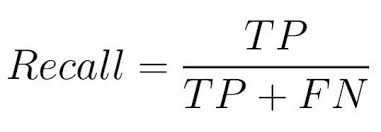

## **Data Understanding**

Untuk mendukung analisis, dipakai dua dataset permintaan hotel, yaitu resort hotel (H1) dan city hotel (H2), yang memiliki struktur data yang sama dengan 31 variabel. Dataset H1 terdiri dari 40.060 observasi dan H2 sebanyak 79.330 observasi, di mana setiap observasi merepresentasikan satu pemesanan hotel. Data ini mencakup pemesanan dengan tanggal kedatangan antara 1 Juli 2015 hingga 31 Agustus 2017.

Data Source: https://www.sciencedirect.com/science/article/pii/S2352340918315191

| Attribute | Description |
|------------|---------------|
| **hotel** | Resort Hotel or City Hotel. |
| **is_canceled** | Value indicating if the booking was canceled (1) or not (0). |
| **lead_time** | Number of days that elapsed between the entering date of the booking into the PMS and the arrival date. |
| **arrival_date_year** | Year of arrival date. |
| **arrival_date_month** | Month of arrival date. |
| **arrival_date_week_number** | Week number of year for arrival date. |
| **arrival_date_day_of_month** | Day of arrival date. |
| **stays_in_weekend_nights** | Number of weekend nights (Saturday or Sunday) the guest stayed or booked to stay at the hotel. |
| **stays_in_week_nights** | Number of week nights (Monday to Friday) the guest stayed or booked to stay at the hotel. |
| **adults** | Number of adults. |
| **babies** | Number of babies. |
| **meal** | Type of meal booked. Categories are presented in standard hospitality meal packages: Undefined/SC – no meal package; BB – Bed & Breakfast; HB – Half board (breakfast and one other meal – usually dinner); FB – Full board (breakfast, lunch and dinner). |
| **country** | Country of origin. |
| **market_segment** | Market segment designation. In categories, the term “TA” means “Travel Agents” and “TO” means “Tour Operators”. |
| **distribution_channel** | Booking distribution channel. The term “TA” means “Travel Agents” and “TO” means “Tour Operators”. |
| **is_repeated_guest** | Value indicating whether the booking was made by a repeated guest (1) or not (0). |
| **previous_cancellations** | Number of previous bookings that were canceled by the customer before the current booking. |
| **previous_bookings_not_canceled** | Number of previous bookings not canceled by the customer before the current booking. |
| **reserved_room_type** | Code representing the room type reserved. The code is used instead of the actual room designation for anonymity purposes. |
| **assigned_room_type** | Code representing the room type assigned to the booking. The assigned room type may differ from the reserved room type due to hotel operational reasons such as overbooking or due to customer requests. |
| **booking_changes** | Number of changes or amendments made to the booking after it was created. |
| **deposit_type** | Type of deposit applied to the booking: No Deposit means no deposit was made; Non Refund means a deposit equal to the total stay cost was made; Refundable means a deposit below the total cost of stay was made. |
| **agent** | Identifier of the travel agency that made the booking. The identifier is anonymized. |
| **company** | Identifier of the company or entity responsible for making or paying for the booking. The identifier is anonymized. |
| **days_in_waiting_list** | Number of days the booking remained on the waiting list before it was confirmed to the customer. |
| **customer_type** | Type of customer: Group indicates the booking is associated with a group; Transient indicates the booking is not part of a group or contract; Transient-party indicates the booking is transient but associated with at least one other transient booking. |
| **adr** | Average Daily Rate, calculated by dividing the total lodging revenue by the total number of staying nights. |
| **required_car_parking_spaces** | Number of car parking spaces required by the customer for the booking. |
| **total_of_special_requests** | Number of special requests made by the customer, such as requesting a twin bed or a high-floor room. |
| **reservation_status** | Final reservation status of the booking, such as Check-Out (the customer checked in and has departed) or No-Show (the customer did not check in but informed the hotel). |
| **reservation_status_date** | Date on which the last reservation status was set, indicating when the booking was canceled or when the customer checked out. |

### Import Library

In [ ]:
# Library
import pandas as pd
import numpy as np

from scipy.stats import shapiro
from scipy.stats import chi2_contingency

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
import missingno
from IPython.display import display

# Feature Engineering
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, LabelEncoder, OrdinalEncoder, MinMaxScaler
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, RobustScaler, MinMaxScaler


# Model Selection
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV,StratifiedKFold,train_test_split, cross_val_score, RandomizedSearchCV
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
import lightgbm as lgb
from sklearn.metrics import f1_score, accuracy_score, recall_score, precision_score, make_scorer
from sklearn.neural_network import MLPClassifier


# Imbalance Dataset
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import RandomOverSampler, SMOTE

# Ignore Warning
import sys
import warnings
if not sys.warnoptions:
    warnings.simplefilter("ignore")
warnings.filterwarnings('ignore')

# Set max columns
pd.set_option('display.max_columns', None)

### Import Dataset

In [ ]:
df = pd.read_csv("hotel_bookings.csv")
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [ ]:
df.shape

(119390, 32)

In [ ]:
# detailed summary of the columns
listItem = []
for col in df.columns :
    listItem.append([col, df[col].dtype, df[col].isna().sum(), round((df[col].isna().sum()/len(df[col])) * 100,2),
                    df[col].nunique(), list(df[col].drop_duplicates().values)]);

dfDesc = pd.DataFrame(columns=['dataFeatures', 'dataType', 'null', 'nullPct', 'unique', 'uniqueSample'],
                     data=listItem)
dfDesc

,dataFeatures,dataType,null,nullPct,unique,uniqueSample
0,hotel,object,0,0.00,2,"[Resort Hotel, City Hotel]"
1,is_canceled,int64,0,0.00,2,"[0, 1]"
2,lead_time,int64,0,0.00,479,"[342, 737, 7, 13, 14, 0, 9, 85, 75, 23, 35, 68..."
3,arrival_date_year,int64,0,0.00,3,"[2015, 2016, 2017]"
4,arrival_date_month,object,0,0.00,12,"[July, August, September, October, November, D..."
5,arrival_date_week_number,int64,0,0.00,53,"[27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 3..."
6,arrival_date_day_of_month,int64,0,0.00,31,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14..."
7,stays_in_weekend_nights,int64,0,0.00,17,"[0, 1, 2, 4, 3, 6, 13, 8, 5, 7, 12, 9, 16, 18,..."
8,stays_in_week_nights,int64,0,0.00,35,"[0, 1, 2, 3, 4, 5, 10, 11, 8, 6, 7, 15, 9, 12,..."
9,adults,int64,0,0.00,14,"[2, 1, 3, 4, 40, 26, 50, 27, 55, 0, 20, 6, 5, 10]"


In [ ]:
numeric_desc = df.describe()
categoric_desc = df.describe(include='object')

display(numeric_desc, categoric_desc)

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


,hotel,arrival_date_month,meal,country,market_segment,distribution_channel,reserved_room_type,assigned_room_type,deposit_type,customer_type,reservation_status,reservation_status_date
count,119390,119390,119390,118902,119390,119390,119390,119390,119390,119390,119390,119390
unique,2,12,5,177,8,5,10,12,3,4,3,926
top,City Hotel,August,BB,PRT,Online TA,TA/TO,A,A,No Deposit,Transient,Check-Out,2015-10-21
freq,79330,13877,92310,48590,56477,97870,85994,74053,104641,89613,75166,1461


In [ ]:
df.groupby('arrival_date_month')['is_canceled'].mean().reset_index(name='cancellation_rate').sort_values('cancellation_rate', ascending=False)

,arrival_date_month,cancellation_rate
6,June,0.414572
0,April,0.407972
8,May,0.396658
11,September,0.391702
10,October,0.380466
1,August,0.377531
5,July,0.374536
2,December,0.349705
3,February,0.334160
7,March,0.321523


## **Data Preparation**

### **Missing Values**

In [ ]:
df.isna().sum()

,0
hotel,0
is_canceled,0
lead_time,0
arrival_date_year,0
arrival_date_month,0
arrival_date_week_number,0
arrival_date_day_of_month,0
stays_in_weekend_nights,0
stays_in_week_nights,0
adults,0


Pada variabel Agent dan Company, nilai NULL tidak dianggap sebagai data hilang, melainkan sebagai kondisi “tidak berlaku”. Nilai NULL pada Agent menunjukkan bahwa reservasi tidak dilakukan melalui agen perjalanan, sedangkan NULL pada Company mengindikasikan bahwa pembayaran tidak ditanggung oleh perusahaan, melainkan oleh pelanggan individu. Sementara itu, nilai NULL pada variabel Children diartikan sebagai tidak adanya anak kecil dalam reservasi tersebut. Adapun nilai NULL pada Country merepresentasikan asal negara yang tidak diketahui

In [ ]:
df['children'] = df['children'].fillna(0)
df['country'] = df['country'].fillna('Unknown')
df['agent'] = df['agent'].fillna(0)
df['company'] = df['company'].fillna(0)

Penanganan nilai NULL dilakukan dengan mengganti Children menjadi 0, serta Agent dan Company menjadi 0, sementara Country diisi sebagai “Unknown”.

### **Duplicate Values**

In [ ]:
df.duplicated().sum()

np.int64(31994)

Meskipun terdapat beberapa data duplikat, data tersebut tidak dihapus karena setiap baris merepresentasikan satu kejadian reservasi yang valid dan tidak tersedia ID unik untuk memastikan duplikasi sebagai kesalahan pencatatan.

### **Filtering**

In [ ]:
df['total_guest'] = df['adults'] + df['children'] + df['babies']
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,total_guest
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,0.0,0.0,0,Transient,0.0,0,0,Check-Out,2015-07-01,2.0
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,0.0,0.0,0,Transient,0.0,0,0,Check-Out,2015-07-01,2.0
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,0.0,0.0,0,Transient,75.0,0,0,Check-Out,2015-07-02,1.0
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,0.0,0,Transient,75.0,0,0,Check-Out,2015-07-02,1.0
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,0.0,0,Transient,98.0,0,1,Check-Out,2015-07-03,2.0


In [ ]:
df[df['total_guest'] == 0]

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,total_guest
2224,Resort Hotel,0,1,2015,October,41,6,0,3,0,0.0,0,SC,PRT,Corporate,Corporate,0,0,0,A,I,1,No Deposit,0.0,174.0,0,Transient-Party,0.00,0,0,Check-Out,2015-10-06,0.0
2409,Resort Hotel,0,0,2015,October,42,12,0,0,0,0.0,0,SC,PRT,Corporate,Corporate,0,0,0,A,I,0,No Deposit,0.0,174.0,0,Transient,0.00,0,0,Check-Out,2015-10-12,0.0
3181,Resort Hotel,0,36,2015,November,47,20,1,2,0,0.0,0,SC,ESP,Groups,TA/TO,0,0,0,A,C,0,No Deposit,38.0,0.0,0,Transient-Party,0.00,0,0,Check-Out,2015-11-23,0.0
3684,Resort Hotel,0,165,2015,December,53,30,1,4,0,0.0,0,SC,PRT,Groups,TA/TO,0,0,0,A,A,1,No Deposit,308.0,0.0,122,Transient-Party,0.00,0,0,Check-Out,2016-01-04,0.0
3708,Resort Hotel,0,165,2015,December,53,30,2,4,0,0.0,0,SC,PRT,Groups,TA/TO,0,0,0,A,C,1,No Deposit,308.0,0.0,122,Transient-Party,0.00,0,0,Check-Out,2016-01-05,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115029,City Hotel,0,107,2017,June,26,27,0,3,0,0.0,0,BB,CHE,Online TA,TA/TO,0,0,0,A,A,1,No Deposit,7.0,0.0,0,Transient,100.80,0,0,Check-Out,2017-06-30,0.0
115091,City Hotel,0,1,2017,June,26,30,0,1,0,0.0,0,SC,PRT,Complementary,Direct,0,0,0,E,K,0,No Deposit,0.0,0.0,0,Transient,0.00,1,1,Check-Out,2017-07-01,0.0
116251,City Hotel,0,44,2017,July,28,15,1,1,0,0.0,0,SC,SWE,Online TA,TA/TO,0,0,0,A,K,2,No Deposit,425.0,0.0,0,Transient,73.80,0,0,Check-Out,2017-07-17,0.0
116534,City Hotel,0,2,2017,July,28,15,2,5,0,0.0,0,SC,RUS,Online TA,TA/TO,0,0,0,A,K,1,No Deposit,9.0,0.0,0,Transient-Party,22.86,0,1,Check-Out,2017-07-22,0.0


In [ ]:
df = df[df['total_guest'] > 0]
df.shape

(119209, 33)

### **Drop Unused Features**

In [ ]:
df.drop(columns=['adults', 'children', 'babies'], inplace=True)
df.shape

(119209, 30)

Karena sudah ada kolom total guest, maka kolom adults, children, dan babies dihapus

In [ ]:
df = df.drop(['reservation_status', 'reservation_status_date', 'assigned_room_type'], axis=1)

Kolom reservation_status, reservation_status_date, dan assigned_room_type dihapus karena berpotensi menyebabkan data leakage, yaitu mengandung informasi yang hanya diketahui setelah kejadian pembatalan atau kedatangan tamu. Informasi pada kolom-kolom ini secara langsung atau tidak langsung menunjukkan apakah pelanggan benar-benar datang (check-out/no-show) atau telah terjadi realisasi kamar.

### **Handle Noisy Data**

In [ ]:
df[df['adr'] < 0]

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
14969,Resort Hotel,0,195,2017,March,10,5,4,6,2,0.0,0,BB,GBR,Groups,Direct,1,0,2,A,H,2,No Deposit,273.0,0.0,0,Transient-Party,-6.38,0,0,Check-Out,2017-03-15


In [ ]:
df = df[df['adr'] >= 0]
df.shape

(119389, 32)

Menghapus row dengan nilai adr < 0 karena dianggap tidak normal

In [ ]:
df[(df['adr'] == 0) & (df['is_canceled'] == 0) & (df['market_segment'] != 'Complementary')]

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,total_guest
0,Resort Hotel,0,342,2015,July,27,1,0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,0.0,0.0,0,Transient,0.0,0,0,Check-Out,2015-07-01,2.0
1,Resort Hotel,0,737,2015,July,27,1,0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,0.0,0.0,0,Transient,0.0,0,0,Check-Out,2015-07-01,2.0
167,Resort Hotel,0,111,2015,July,28,6,0,0,BB,PRT,Online TA,TA/TO,0,0,0,A,H,0,No Deposit,240.0,0.0,0,Transient,0.0,0,2,Check-Out,2015-07-06,2.0
168,Resort Hotel,0,0,2015,July,28,6,0,0,BB,PRT,Direct,Direct,0,0,0,E,H,0,No Deposit,250.0,0.0,0,Transient,0.0,0,0,Check-Out,2015-07-06,1.0
196,Resort Hotel,0,8,2015,July,28,7,0,0,BB,PRT,Direct,Direct,0,0,0,A,A,0,No Deposit,0.0,0.0,0,Transient,0.0,0,1,Check-Out,2015-07-07,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
118029,City Hotel,0,0,2017,August,33,14,0,0,BB,PRT,Direct,Direct,1,0,0,A,A,0,No Deposit,0.0,0.0,0,Transient,0.0,0,0,Check-Out,2017-08-14,2.0
118142,City Hotel,0,504,2017,August,32,12,2,1,BB,PRT,Offline TA/TO,TA/TO,0,0,0,A,A,3,No Deposit,229.0,0.0,0,Transient-Party,0.0,0,0,Check-Out,2017-08-15,1.0
118631,City Hotel,0,78,2017,August,34,23,0,0,BB,PRT,Offline TA/TO,TA/TO,0,0,0,A,K,7,No Deposit,98.0,0.0,0,Transient-Party,0.0,0,0,Check-Out,2017-08-23,1.0
118963,City Hotel,0,1,2017,August,35,27,0,0,BB,PRT,Direct,Direct,0,0,0,A,A,0,No Deposit,0.0,0.0,0,Transient,0.0,0,0,Check-Out,2017-08-27,2.0


In [ ]:
df[(df['is_canceled'] == 0) & (df['reservation_status'] == 'Check-Out') & (df['stays_in_weekend_nights'] == 0) &
        (df['stays_in_week_nights'] == 0)]

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,total_guest
0,Resort Hotel,0,342,2015,July,27,1,0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,0.0,0.0,0,Transient,0.0,0,0,Check-Out,2015-07-01,2.0
1,Resort Hotel,0,737,2015,July,27,1,0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,0.0,0.0,0,Transient,0.0,0,0,Check-Out,2015-07-01,2.0
167,Resort Hotel,0,111,2015,July,28,6,0,0,BB,PRT,Online TA,TA/TO,0,0,0,A,H,0,No Deposit,240.0,0.0,0,Transient,0.0,0,2,Check-Out,2015-07-06,2.0
168,Resort Hotel,0,0,2015,July,28,6,0,0,BB,PRT,Direct,Direct,0,0,0,E,H,0,No Deposit,250.0,0.0,0,Transient,0.0,0,0,Check-Out,2015-07-06,1.0
196,Resort Hotel,0,8,2015,July,28,7,0,0,BB,PRT,Direct,Direct,0,0,0,A,A,0,No Deposit,0.0,0.0,0,Transient,0.0,0,1,Check-Out,2015-07-07,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115483,City Hotel,0,15,2017,July,27,6,0,0,SC,FRA,Direct,Direct,0,0,0,A,A,0,No Deposit,14.0,0.0,0,Transient-Party,0.0,0,0,Check-Out,2017-07-06,1.0
117701,City Hotel,0,0,2017,August,32,8,0,0,BB,PRT,Offline TA/TO,TA/TO,1,0,0,A,A,0,No Deposit,262.0,0.0,0,Transient,0.0,0,0,Check-Out,2017-08-08,2.0
118029,City Hotel,0,0,2017,August,33,14,0,0,BB,PRT,Direct,Direct,1,0,0,A,A,0,No Deposit,0.0,0.0,0,Transient,0.0,0,0,Check-Out,2017-08-14,2.0
118631,City Hotel,0,78,2017,August,34,23,0,0,BB,PRT,Offline TA/TO,TA/TO,0,0,0,A,K,7,No Deposit,98.0,0.0,0,Transient-Party,0.0,0,0,Check-Out,2017-08-23,1.0


In [ ]:
df= df[
    ~(
        (df['is_canceled'] == 0) &
        (df['adr'] == 0) &
        (~df['market_segment'].isin(['Complementary', 'Corporate', 'Aviation']))
    )
]



Data dengan kondisi reservasi tidak dibatalkan (is_canceled = 0) dan memiliki ADR = 0 seharusnya hanya muncul pada market segment gratis seperti Complementary, Corporate, atau Aviation. Namun, pada dataset ditemukan observasi dengan ADR = 0 yang berasal dari market segment berbayar. Oleh karena itu, data tersebut dihapus.

In [ ]:
df= df[
    ~(
        (df['is_canceled'] == 0) &
        (df['reservation_status'] == 'Check-Out') &
        (df['stays_in_weekend_nights'] == 0) &
        (df['stays_in_week_nights'] == 0)
    )
]

Reservasi Check-Out dan is_canceled = 0 menunjukkan bahwa tamu telah menginap di hotel. Oleh karena itu, jumlah malam menginap (weekday dan weekend) seharusnya lebih dari nol. Namun, pada dataset ditemukan data dengan total malam menginap sama dengan nol. Oleh karena itu, data tersebut perlu dihapus.

In [ ]:
df.shape

(118175, 30)

### **Cardinality**

In [ ]:
df = df.drop(['agent', 'company', 'country'], axis=1)
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,meal,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,booking_changes,deposit_type,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,total_guest
2,Resort Hotel,0,7,2015,July,27,1,0,1,BB,Direct,Direct,0,0,0,A,0,No Deposit,0,Transient,75.0,0,0,1.0
3,Resort Hotel,0,13,2015,July,27,1,0,1,BB,Corporate,Corporate,0,0,0,A,0,No Deposit,0,Transient,75.0,0,0,1.0
4,Resort Hotel,0,14,2015,July,27,1,0,2,BB,Online TA,TA/TO,0,0,0,A,0,No Deposit,0,Transient,98.0,0,1,2.0
5,Resort Hotel,0,14,2015,July,27,1,0,2,BB,Online TA,TA/TO,0,0,0,A,0,No Deposit,0,Transient,98.0,0,1,2.0
6,Resort Hotel,0,0,2015,July,27,1,0,2,BB,Direct,Direct,0,0,0,C,0,No Deposit,0,Transient,107.0,0,0,2.0


Kolom agent, company, dan country dihapus karena memiliki cardinality yang sangat tinggi, dengan jumlah nilai unik masing-masing sebesar 16,340 (agent), 112,593 (company), dan 488 (country). Cardinality yang tinggi berpotensi meningkatkan kompleksitas model, menyebabkan overfitting, serta menambah beban komputasi tanpa memberikan informasi prediktif yang signifikan.

### **Encoding & Scaling**

In [ ]:
# Convert Month into numerical values
month_mapping = {
    'January':1, 'February':2, 'March':3, 'April':4, 'May':5, 'June':6,
    'July':7, 'August':8, 'September':9, 'October':10, 'November':11, 'December':12
}

df['arrival_date_month'] = df['arrival_date_month'].map(month_mapping)

Kolom arrival_date_month dikonversi dari format kategorikal (nama bulan) ke format numerik dengan konversi manual karena urutan bulan sudah jelas dan konsisten. Pendekatan ini setara dengan ordinal encoding, lebih sederhana, dan tidak menambah kompleksitas pipeline tanpa kehilangan informasi urutan.

In [ ]:
df.select_dtypes(include='object').columns

Index(['hotel', 'meal', 'market_segment', 'distribution_channel',
       'reserved_room_type', 'deposit_type', 'customer_type'],
      dtype='object')

In [ ]:
df.select_dtypes(include='number').columns

Index(['is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month',
       'arrival_date_week_number', 'arrival_date_day_of_month',
       'stays_in_weekend_nights', 'stays_in_week_nights', 'is_repeated_guest',
       'previous_cancellations', 'previous_bookings_not_canceled',
       'booking_changes', 'days_in_waiting_list', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'total_guest'],
      dtype='object')

In [ ]:
# Categorical features
cat_features = [
    'hotel', 'meal', 'market_segment',
    'distribution_channel', 'reserved_room_type',
    'deposit_type', 'customer_type'
]
# Num features that will be scaled
num_scaled = ['lead_time', 'adr', 'days_in_waiting_list']

| Teknik                | Definisi                                                                 | Alasan Penggunaan                                                                 |
|----------------------|---------------------------------------------------------------------------|----------------------------------------------------------------------------------|
| Robust Scaler        | Teknik penskalaan yang menggunakan median dan Interquartile Range (IQR) untuk menormalkan fitur numerik. | Karena fitur numerik memiliki banyak outlier, sehingga lebih stabil dan tidak sensitif terhadap nilai ekstrem. |
| One-Hot Encoding     | Metode encoding yang mengubah variabel kategorikal menjadi beberapa kolom biner numerik. | Untuk mengubah fitur kategorikal yang tidak memiliki urutan (non-ordinal) menjadi numerik tanpa menciptakan hubungan ordinal yang tidak tepat. |
| Remainder (Passthrough) | Mekanisme untuk meneruskan kolom tertentu tanpa dilakukan transformasi apa pun. | Untuk mempertahankan kolom yang sudah berbentuk numerik diskrit dan tidak bersifat kontinu, sehingga tidak perlu dilakukan scaling atau encoding. |


In [ ]:
transformer = ColumnTransformer(
    transformers=[
        ('scale', RobustScaler(), num_scaled),
        ('encode', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_features)
    ],
    remainder='passthrough'
)

### **Imbalance**

In [ ]:
pd.Series(df['is_canceled']).value_counts(normalize=True)

,proportion
is_canceled,
0,0.625987
1,0.374013


proporsi kelas target termasuk mild imbalance, relatif seimbang (minority class ±37%)

Random Oversampling digunakan untuk menangani ketidakseimbangan kelas yang bersifat ringan (mild imbalance) pada variabel target is_canceled, di mana proporsi pembatalan berada pada kisaran ±37%. Pada kondisi ini, Random Oversampling sudah memadai karena dapat menyeimbangkan distribusi kelas tanpa menciptakan data sintetis baru, sehingga tetap menjaga karakteristik asli data.

In [ ]:
from imblearn.over_sampling import RandomOverSampler
ros = RandomOverSampler(random_state=42)

### **Data Splitting**

In [ ]:
# define feature and target
X = df.drop("is_canceled", axis=1)
y = df["is_canceled"]

# splitting the data into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, shuffle=True, random_state=42
)

print(f'X_size: {X.shape}, y_size: {y.shape}')

X_size: (118175, 23), y_size: (118175,)


Parameter `stratify=y` digunakan untuk **menjaga proporsi kelas pembatalan tetap konsisten** pada data latih dan data uji, sehingga evaluasi model menjadi lebih representatif.  
Penggunaan `shuffle=True` dan `random_state=42` bertujuan untuk memastikan **pembagian data yang acak dan reprodusibel**.

## **Modeling & Evaluation**

### **Model Benchmarking**

| Model               | Alasan Penggunaan                                                                 |
|---------------------|-----------------------------------------------------------------------------------|
| Logistic Regression | Sederhana dan efektif untuk dataset kecil; mudah diinterpretasikan.              |
| K-Nearest Neighbors (KNN) | Model non-parametrik yang fleksibel dan mampu menangkap berbagai pola data. |
| Decision Tree       | Cepat dan sangat mudah diinterpretasikan; mampu memodelkan hubungan linear dan non-linear. |
| Random Forest       | Metode ensemble (bagging) yang meningkatkan akurasi, mengurangi overfitting, dan robust terhadap noise. |
| XGBoost             | Metode boosting dengan akurasi tinggi; mengurangi bias dan memiliki regularisasi. |
| AdaBoost            | Mengurangi bias dengan menggabungkan beberapa weak learner menjadi model yang kuat. |
| Gradient Boosting   | Fleksibel dan efektif untuk berbagai pola data dengan fokus pada pengurangan bias. |
| LightGBM (LGBM)     | Boosting berbasis histogram yang cepat dan efisien, terutama untuk dataset berukuran besar. |


In [ ]:
lg = LogisticRegression(random_state = 42)
knn = KNeighborsClassifier()
dt = DecisionTreeClassifier(random_state = 42)
rf = RandomForestClassifier(random_state = 42)
xgb = XGBClassifier(random_state = 42)
adb = AdaBoostClassifier(random_state = 42)
gb = GradientBoostingClassifier(random_state = 42)
lgbm = lgb.LGBMClassifier(random_state = 42)

#### Train Data

In [ ]:
models = [lg, knn, dt, rf, xgb, adb, gb, lgbm]
score = []
mean = []
std = []

for model in models:
    skfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    estimator = Pipeline([
        ('preprocess', transformer),
        ('imbalance', ros),
        ('model', model)
    ])

    model_cv=cross_val_score(estimator,X_train,y_train,cv=skfold,scoring='recall')
    score.append(model_cv)
    mean.append(model_cv.mean())
    std.append(model_cv.std())

pd.DataFrame({'model': ['Logistic Regression', 'KNN', 'Decision Tree',
              'Random Forest', 'XGBoost','AdaBoost' ,'GradienBoosting', 'LightGBM'], 'mean_recall': mean,'std': std}).set_index('model').sort_values(by='mean_recall', ascending=False)

[LightGBM] [Info] Number of positive: 41426, number of negative: 41426
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.066377 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 886
[LightGBM] [Info] Number of data points in the train set: 82852, number of used features: 42
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Number of positive: 41426, number of negative: 41426
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.092499 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 895
[LightGBM] [Info] Number of data points in the train set: 82852, number of used features: 42
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Number of positive: 41426, number of negat

,mean_recall,std
model,,
XGBoost,0.785481,0.007105
LightGBM,0.777789,0.010707
Random Forest,0.774169,0.004536
Decision Tree,0.759592,0.001949
KNN,0.748732,0.003350
AdaBoost,0.707260,0.073830
Logistic Regression,0.705098,0.017308
GradienBoosting,0.703740,0.012967


Berdasarkan hasil benchmark terhadap 8 model, terlihat bahwa XGBoost merupakan model dengan skor rata-rata recall yang tertinggi.

#### Test Data

In [ ]:
recall_score_test = []

for model in models:
    estimator = Pipeline([
        ('preprocess', transformer),
        ('imbalance', ros),
        ('model', model)
    ])

    estimator.fit(X_train, y_train)
    y_pred = estimator.predict(X_test)

    score = recall_score(y_test, y_pred)
    recall_score_test.append(score)

pd.DataFrame({
    'model': ['Logistic Regression', 'KNN', 'Decision Tree',
              'Random Forest', 'XGBoost','AdaBoost' ,'GradientBoosting', 'LightGBM'],
    'test_recall': recall_score_test
}).set_index('model').sort_values(by='test_recall', ascending=False)

[LightGBM] [Info] Number of positive: 51783, number of negative: 51783
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.032909 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 902
[LightGBM] [Info] Number of data points in the train set: 103566, number of used features: 42
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000


,test_recall
model,
XGBoost,0.787104
Random Forest,0.783032
LightGBM,0.779412
AdaBoost,0.769608
Decision Tree,0.761916
KNN,0.757617
Logistic Regression,0.715762
GradientBoosting,0.712142


Hasil evaluasi pada data uji (test set) menunjukkan bahwa XGBoost kembali memperoleh nilai recall tertinggi dibandingkan model lainnya. Konsistensi performa ini, baik pada tahap cross-validation maupun pengujian data test, mengindikasikan bahwa XGBoost memiliki kemampuan generalisasi yang lebih baik dalam mendeteksi

## **Hyperparameter Tuning**

Berdasarkan hasil recall pada benchmark sebelumnya, dapat dilihat bahwa performa model masih kurang tinggi dan dapat ditingkatan dengan hyperparameter tuning.

Model yang akan dilakukan proses hyperparameter tuning adalah XGBoost, karena memiliki performa tertinggi secara keseluruhan, serta Random Forest, yang menunjukkan performa recall tinggi pada data uji setelah XGBoost, sehingga dianggap memiliki kemampuan generalisasi yang lebih baik.

Metode yang dipakai untuk mencari kombinasi paramater yang terbaik pada model adalah **GridSearch**. metode ini mencoba semua kombinasi nilai hyperparameter yang tersedia, lalu mengevaluasi kinerjanya (dengan cross-validation) untuk menemukan konfigurasi yang menghasilkan performa terbaik.

### **XGBoost**

In [ ]:
# XGB Pipeline
xgb_pipeline = Pipeline([
    ('preprocessing', transformer),
    ('imbalance', ros),
    ('model', xgb)
])


# XGB Prameter Grid
xgb_param = {
    'model__n_estimators': [200, 300],
    'model__max_depth': [4, 6],
    'model__learning_rate': [0.5, 0.1],
    'model__subsample': [0.8, 1.0],
    'model__colsample_bytree': [0.3, 0.5],
    'model__scale_pos_weight': [1.3, 1.5]
}

# Tuning Pipeline
xgb_grid = GridSearchCV(
    estimator=xgb_pipeline,
    param_grid =xgb_param,
    scoring='recall',
    cv=skfold,
    n_jobs=-1

)

# Fiiting
xgb_grid.fit(X_train, y_train)

print("Best Recall Score (XGBosst):", xgb_grid.best_score_)
print("Best Parameters:", xgb_grid.best_params_)

Best Recall Score (XGBosst): 0.8527427496965142
Best Parameters: {'model__colsample_bytree': 0.5, 'model__learning_rate': 0.1, 'model__max_depth': 6, 'model__n_estimators': 200, 'model__scale_pos_weight': 1.5, 'model__subsample': 1.0}


In [ ]:
# Fit non-tuning
xgb_pipeline.fit(X_train, y_train)

# Predict non tuning
y_train_pred_xgb = xgb_pipeline.predict(X_train)
y_test_pred_xgb  = xgb_pipeline.predict(X_test)

# calculate recall score
recall_train_non_tune = recall_score(y_train, y_train_pred_xgb)
recall_test_non_tune  = recall_score(y_test, y_test_pred_xgb)


# Tuned RF
# RF After Hyperprameter tuning
best_xgb = xgb_grid.best_estimator_

# Fitting
best_xgb.fit(X_train, y_train)

# Predict t
y_train_pred_tuned_xgb = best_xgb.predict(X_train)
y_test_pred_tuned_xgb  = best_xgb.predict(X_test)

recall_train_tune = recall_score(y_train, y_train_pred_tuned_xgb)
recall_test_tune  = recall_score(y_test, y_test_pred_tuned_xgb)


comparison_df = pd.DataFrame({
    'Model': ['XgBoost Non-Tuning', 'XgBoost Tuning'],
    'Recall_Train': [recall_train_non_tune, recall_train_tune],
    'Recall_Test':  [recall_test_non_tune, recall_test_tune]
})

comparison_df

,Model,Recall_Train,Recall_Test
0,XgBoost Non-Tuning,0.818255,0.787104
1,XgBoost Tuning,0.867449,0.848492


Hasil tuning menunjukkan bahwa recall pada XGBoost meningkat dibandingkan sebelum tuning.

### **Random Forest**

In [ ]:
# RF Pipeline
rf_pipeline = Pipeline([
    ('preprocessing', transformer),
    ('imbalance', ros),
    ('model', rf)
])


# RF Prameter Grid
rf_param = {
    'model__n_estimators': [100,200],
    'model__max_depth': [10, 15],
    'model__min_samples_split': [3,5],
    'model__min_samples_leaf': [2, 4],
    'model__class_weight': [{0: 1, 1: 1.3}, {0: 1, 1: 1.5}
    ]
}

# Tuning Pipeline
rf_grid = GridSearchCV(
    estimator=rf_pipeline,
    param_grid =rf_param,
    scoring='recall',
    cv=skfold,
    n_jobs=-1

)

# Fiiting
rf_grid.fit(X_train, y_train)

print("Best Recall Score (Random Forest):", rf_grid.best_score_)
print("Best Parameters:", rf_grid.best_params_)

Best Recall Score (Random Forest): 0.8752387531083847
Best Parameters: {'model__class_weight': {0: 1, 1: 1.5}, 'model__max_depth': 10, 'model__min_samples_leaf': 2, 'model__min_samples_split': 5, 'model__n_estimators': 100}


In [ ]:
# Fit non-tuning
rf_pipeline.fit(X_train, y_train)

# Predict non tuning
y_train_pred_rf = rf_pipeline.predict(X_train)
y_test_pred_rf  = rf_pipeline.predict(X_test)

# calculate recall score
recall_train_non_tune_rf = recall_score(y_train, y_train_pred_rf)
recall_test_non_tune_rf  = recall_score(y_test, y_test_pred_rf)


# Tuned RF
# RF After Hyperprameter tuning
best_rf = rf_grid.best_estimator_

# Fitting
best_rf.fit(X_train, y_train)

# Predict t
y_train_pred_tuned_rf = best_rf.predict(X_train)
y_test_pred_tuned_rf = best_rf.predict(X_test)

recall_train_tune_rf = recall_score(y_train, y_train_pred_tuned_rf)
recall_test_tune_rf  = recall_score(y_test, y_test_pred_tuned_rf)


comparison_df = pd.DataFrame({
    'Model': ['Random Forest Non-Tuning', 'Random Forest Tuning'],
    'Recall_Train': [recall_train_non_tune_rf, recall_train_tune_rf],
    'Recall_Test':  [recall_test_non_tune_rf, recall_test_tune_rf]
})

comparison_df

,Model,Recall_Train,Recall_Test
0,Random Forest Non-Tuning,0.991079,0.783032
1,Random Forest Tuning,0.880378,0.871719


### **Model Evaluation**

#### **Default XGBoost**


 Default Decision Tree Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.86      0.87     22193
           1       0.78      0.79      0.78     13260

    accuracy                           0.84     35453
   macro avg       0.82      0.83      0.82     35453
weighted avg       0.84      0.84      0.84     35453



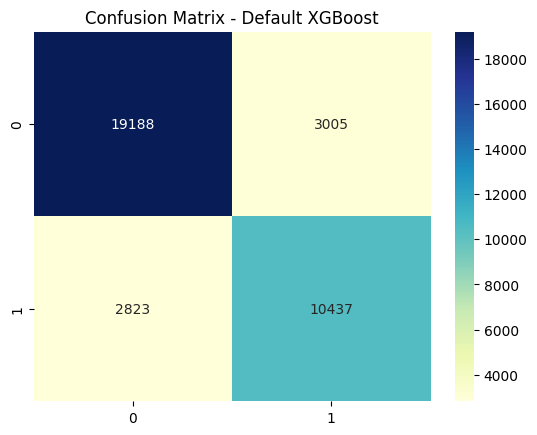


Default XGBoost Metric Score:
Accuracy : 0.8356
Precision: 0.7764
Recall   : 0.7871
F1 Score : 0.7817
AUC ROC: 0.9110827344292586


In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import roc_auc_score

pipeline = Pipeline([
    ('preprocess', transformer),
    ('imbalance', ros),
    ('model', xgb)
])

pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)


# Classification Report
print("\n Default Decision Tree Classification Report:")
print(classification_report(y_test, y_pred))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap="YlGnBu")
plt.title("Confusion Matrix - Default XGBoost")
plt.show()

# Metric Score
accuracy  = accuracy_score(y_test, y_test_pred_xgb)
precision = precision_score(y_test, y_test_pred_xgb)
recall    = recall_score(y_test, y_test_pred_xgb)
f1        = f1_score(y_test, y_test_pred_xgb)
auc_xgb = roc_auc_score(y_test, xgb_pipeline.predict_proba(X_test)[:,1])

print("\nDefault XGBoost Metric Score:")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print("AUC ROC:", auc_xgb)


#### **Tuned XGBoost**


 Tuned XGBoost Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.77      0.83     22193
           1       0.69      0.85      0.76     13260

    accuracy                           0.80     35453
   macro avg       0.79      0.81      0.79     35453
weighted avg       0.82      0.80      0.80     35453



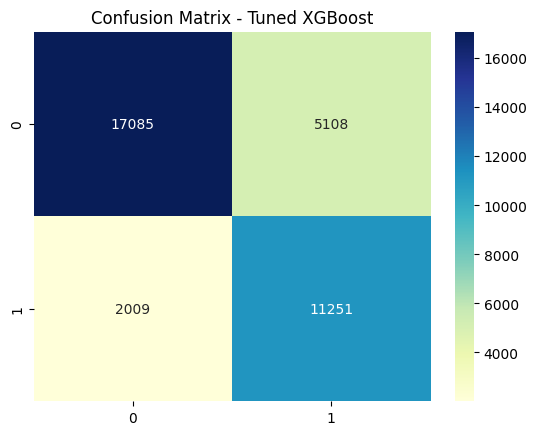


Tuned XGBoost Metric Score:
Accuracy : 0.7993
Precision: 0.6878
Recall   : 0.8485
F1 Score : 0.7597
AUC ROC: 0.9067908032093878


In [ ]:
# Classification Report
print("\n Tuned XGBoost Classification Report:")
print(classification_report(y_test, y_test_pred_tuned_xgb))

# Confusion Matrix
cm = confusion_matrix(y_test, y_test_pred_tuned_xgb)
sns.heatmap(cm, annot=True, fmt='d', cmap="YlGnBu")
plt.title("Confusion Matrix - Tuned XGBoost")
plt.show()

# Metric Score
accuracy_tuned_xgb  = accuracy_score(y_test, y_test_pred_tuned_xgb)
precision_tuned_xgb = precision_score(y_test, y_test_pred_tuned_xgb)
recall_tuned_xgb  = recall_score(y_test, y_test_pred_tuned_xgb)
f1_tuned_xgb  = f1_score(y_test,y_test_pred_tuned_xgb)
auc_xgb_tuned = roc_auc_score(y_test, best_xgb.predict_proba(X_test)[:,1])

print("\nTuned XGBoost Metric Score:")
print(f"Accuracy : {accuracy_tuned_xgb:.4f}")
print(f"Precision: {precision_tuned_xgb:.4f}")
print(f"Recall   : {recall_tuned_xgb:.4f}")
print(f"F1 Score : {f1_tuned_xgb:.4f}")
print("AUC ROC:", auc_xgb_tuned)


#### **Default Random Forest**


 Default Random Forest Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.91      0.89     22193
           1       0.84      0.78      0.81     13260

    accuracy                           0.86     35453
   macro avg       0.86      0.85      0.85     35453
weighted avg       0.86      0.86      0.86     35453



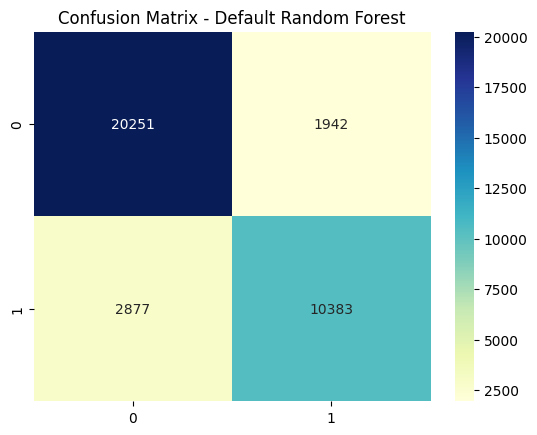


Default Random Forest Metric Score:
Accuracy : 0.8641
Precision: 0.8424
Recall   : 0.7830
F1 Score : 0.8116
AUC ROC: 0.9296261138827421


In [ ]:
pipeline = Pipeline([
    ('preprocess', transformer),
    ('smote', ros),
    ('model', rf)
])

pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)


# Classification Report
print("\n Default Random Forest Classification Report:")
print(classification_report(y_test, y_pred))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap="YlGnBu")
plt.title("Confusion Matrix - Default Random Forest")
plt.show()

# Metric Score
accuracy  = accuracy_score(y_test, y_test_pred_rf)
precision = precision_score(y_test, y_test_pred_rf)
recall    = recall_score(y_test, y_test_pred_rf)
f1        = f1_score(y_test, y_test_pred_rf)
auc_rf = roc_auc_score(y_test, rf_pipeline.predict_proba(X_test)[:,1])

print("\nDefault Random Forest Metric Score:")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print("AUC ROC:", auc_rf)


#### **Tuned Random Forest**


 Tuned Random Forest Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.68      0.77     22193
           1       0.62      0.87      0.72     13260

    accuracy                           0.75     35453
   macro avg       0.76      0.78      0.75     35453
weighted avg       0.79      0.75      0.75     35453



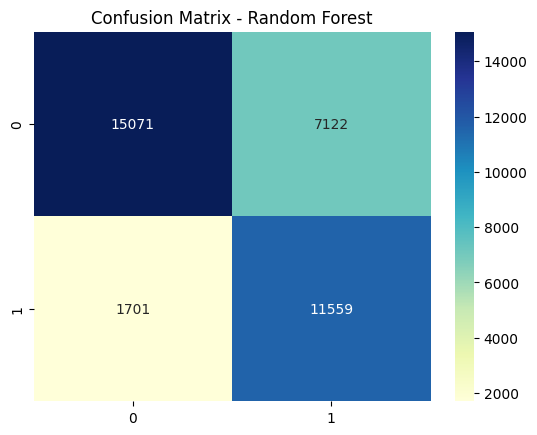


Tuned Random Forest Metric Score:
Accuracy : 0.7511
Precision: 0.6188
Recall   : 0.8717
F1 Score : 0.7238
AUC ROC: 0.8889541710018358


In [ ]:
# Classification Report
print("\n Tuned Random Forest Classification Report:")
print(classification_report(y_test, y_test_pred_tuned_rf))

# Confusion Matrix
cm = confusion_matrix(y_test, y_test_pred_tuned_rf)
sns.heatmap(cm, annot=True, fmt='d', cmap="YlGnBu")
plt.title("Confusion Matrix - Random Forest")
plt.show()

# Metric Score
accuracy_tuned_rf  = accuracy_score(y_test, y_test_pred_tuned_rf)
precision_tuned_rf= precision_score(y_test, y_test_pred_tuned_rf)
recall_tuned_rf  = recall_score(y_test, y_test_pred_tuned_rf)
f1_tuned_rf  = f1_score(y_test,y_test_pred_tuned_rf)
auc_rf_tuned = roc_auc_score(y_test, best_rf.predict_proba(X_test)[:,1])

print("\nTuned Random Forest Metric Score:")
print(f"Accuracy : {accuracy_tuned_rf:.4f}")
print(f"Precision: {precision_tuned_rf:.4f}")
print(f"Recall   : {recall_tuned_rf:.4f}")
print(f"F1 Score : {f1_tuned_rf:.4f}")
print("AUC ROC:", auc_rf_tuned)


#### Tuned Decision Tree


 Tuned Decision Tree Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.58      0.71     22193
           1       0.56      0.90      0.69     13260

    accuracy                           0.70     35453
   macro avg       0.74      0.74      0.70     35453
weighted avg       0.78      0.70      0.70     35453



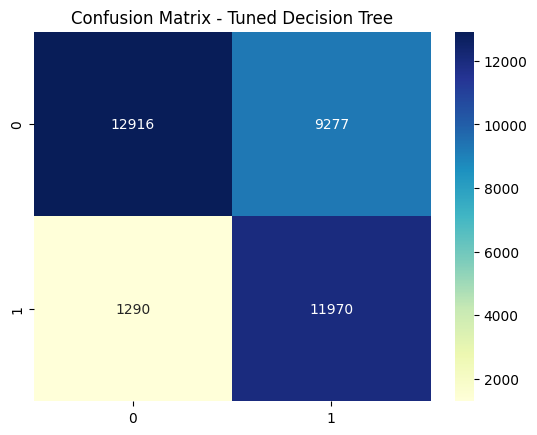


Tuned Decision Tree Metric Score:
Accuracy : 0.7019
Precision: 0.5634
Recall   : 0.9027
F1 Score : 0.6938
AUC ROC: 0.8673518561523788


In [ ]:

# Classification Report
print("\n Tuned Decision Tree Classification Report:")
print(classification_report(y_test, y_test_pred_tuned_dt))

# Confusion Matrix
cm = confusion_matrix(y_test, y_test_pred_tuned_dt)
sns.heatmap(cm, annot=True, fmt='d', cmap="YlGnBu")
plt.title("Confusion Matrix - Tuned Decision Tree")
plt.show()

# Metric Score
accuracy_tuned  = accuracy_score(y_test, y_test_pred_tuned_dt)
precision_tuned = precision_score(y_test, y_test_pred_tuned_dt)
recall_tuned  = recall_score(y_test, y_test_pred_tuned_dt)
f1_tuned  = f1_score(y_test,y_test_pred_tuned_dt)
auc_dt_tuned = roc_auc_score(y_test, best_dt.predict_proba(X_test)[:,1])

print("\nTuned Decision Tree Metric Score:")
print(f"Accuracy : {accuracy_tuned:.4f}")
print(f"Precision: {precision_tuned:.4f}")
print(f"Recall   : {recall_tuned:.4f}")
print(f"F1 Score : {f1_tuned:.4f}")
print("AUC ROC:", auc_dt_tuned)


- cek duplikat lagi

## **Final Model**

In [ ]:
summary = pd.DataFrame({
    "Model": ["XGBoost (Tuned)", "Random Forest (Tuned)"],
    "Accuracy":  [accuracy_tuned_xgb, accuracy_tuned_rf],
    "Precision": [precision_tuned_xgb, precision_tuned_rf],
    "Recall": [recall_tuned_xgb, recall_tuned_rf],
    "F1 Score": [f1_tuned_xgb, f1_tuned_rf],
    "ROC AUC": [auc_xgb_tuned, auc_rf_tuned]
})

summary = summary.set_index("Model")
summary

,Accuracy,Precision,Recall,F1 Score,ROC AUC
Model,,,,,
XGBoost (Tuned),0.799255,0.687756,0.848492,0.759715,0.906791
Random Forest (Tuned),0.751135,0.618757,0.871719,0.723772,0.888954


Meskipun Random Forest menunjukkan nilai recall yang sedikit lebih tinggi, XGBoost (Tuned) dipilih sebagai model utama karena secara keseluruhan memberikan konsistensi performa terbaik di seluruh metrik evaluasi. Berdasarkan hasil benchmarking, nilai mean recall tertinggi dicapai oleh XGBoost, diikuti RF. Selain itu, XGBoost menunjukkan keseimbangan yang lebih baik antara Precision, F1-Score, dan ROC AUC, sehingga model ini lebih handal secara umum dalam prediksi kelas positif sekaligus membedakan kelas positif dan negatif.

XGBoost (Extreme Gradient Boosting) adalah algoritma machine learning berbasis gradient boosting, yang bekerja dengan cara membangun model secara bertahap (iteratif) menggunakan kumpulan decision tree.

Pada awal proses, XGBoost membangun sebuah decision tree sederhana untuk memprediksi target. Setelah itu, model akan mengevaluasi kesalahan (error) dari prediksi tersebut. Decision tree berikutnya kemudian dilatih untuk memperbaiki kesalahan yang dibuat oleh model sebelumnya. Proses ini diulang hingga mencapai jumlah tree tertentu atau hingga performa model tidak lagi meningkat secara signifikan.

Algoritma ini menerapkan regularisasi L1 dan L2 untuk mengontrol kompleksitas model, sehingga model menjadi lebih stabil dan mampu melakukan generalisasi dengan baik. Selain itu, XGBoost menggunakan tree pruning untuk membatasi kedalaman pohon keputusan agar model tidak terlalu kompleks. XGBoost juga mendukung parallel processing, yang memungkinkan proses pelatihan berjalan lebih cepat dengan memanfaatkan banyak core CPU. (https://medium.com/low-code-for-advanced-data-science/xgboost-explained-a-beginners-guide-095464ad418f

https://medium.com/@ml.enesguler/understanding-xgboost-from-basics-to-advanced-insights-d88536d87038)



              precision    recall  f1-score   support

           0       0.90      0.77      0.83     22193
           1       0.69      0.85      0.76     13260

    accuracy                           0.80     35453
   macro avg       0.79      0.81      0.80     35453
weighted avg       0.82      0.80      0.81     35453



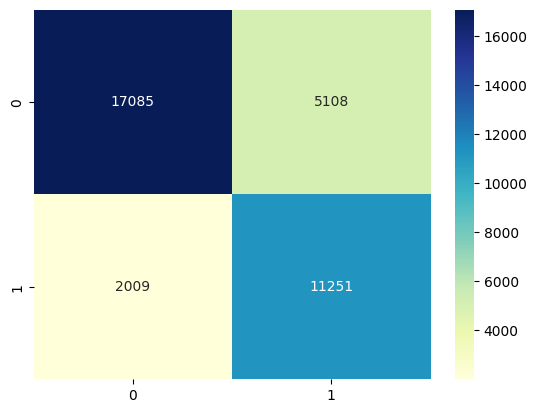

In [ ]:
final_model = Pipeline([
    ('preprocessing',  transformer),
    ('imbalance', ros),
    ('model', XGBClassifier(
        learning_rate=0.1,
        max_depth = 6,
        n_estimators = 200,
        subsample = 1.0,
        colsample_bytree = 0.5,
        scale_pos_weight = 1.5
        ))
])


final_model.fit(X_train, y_train)

y_pred_final = final_model.predict(X_test)
print(classification_report(y_test, y_pred_final))


sns.heatmap(confusion_matrix(y_test, y_test_pred_tuned_xgb), annot=True, fmt="d", cmap="YlGnBu")
plt.show()

Classification report tersebut menunjukkan bahwa dengan model XGBoost yang telah di tuning,

- Model dapat mendeteksi sebagian besar pelanggan yang akan cancel (recall = 85%). Dengan begitu, hotel bisa melakukan efisiensi operasional, perencanaan permintaan lebih akurat, menyesuaikan strategi overbooking atau menargetkan pelanggan lain untuk mengisi kamar kosong, menawarkan promosi, upgrade, atau flexible booking kepada pelanggan berisiko cancel untuk meminimalkan lost revenue
- Model dapat memiliki ketepatan prediksi yang cancel sebesar 69%. Ada 31% pelanggan yang diprediksi akan cancel tapi sebenarnya tidak cancel (false positive). Artinya ada pelanggan yang tidak cancel "tersasar" dalam program penawaran preventif atau promo. Dengan begitu, biaya promo mungkin akan lebih besar dari seharusnya, tapi tetap lebih kecil dibanding potensi kerugian akibat cancel. Dengan begitu, ini dapat dikatakan sebagai trade-off yang masih normal untuk mengurangi cancel rate.

Berdasarkan **confusion matrixnya**, dapat diketahui:

1. **True positive:** Jumlah pelanggan yang aktualnya cancel dan diprediksi akan cancel sebanyak 11,251
2. **True Negative:** Jumlah pelanggan yang aktualnya tidak cancel dan diprediksi tidak cancel sebanyak 17,085
3. **False Positive:** Jumlah pelanggan yang tidak cancel, tetapi diprediksi cancel sebanyak 5,108
4. **False Negative:** Jumlah pelanggn  yang cancel, namun diprediksi tidak cancel sebayak 2,009
5. **False Positive Rate:** 23%
6. **False Negative Rate:** 15%

## **Model Interpretability**

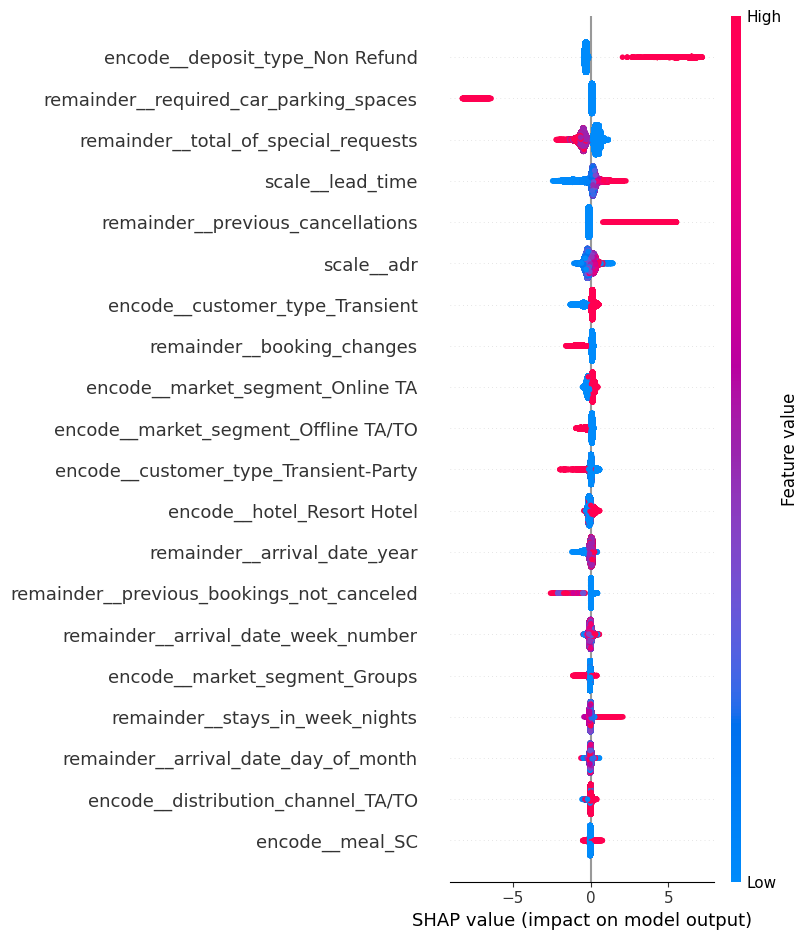

In [ ]:
import shap
X_train_transformed = best_model.named_steps['preprocessing'].transform(X_train)

# Jadi DataFrame biar kolom jelas
X_train_transformed_df = pd.DataFrame(
    X_train_transformed,
    columns=best_xgb.named_steps['preprocessing'].get_feature_names_out()
)

# TreeExplainer pakai model
explainer = shap.TreeExplainer(best_xgb.named_steps['model'])
shap_values = explainer.shap_values(X_train_transformed_df)
shap.summary_plot(shap_values, X_train_transformed_df)

Berdasarkan hasil analisis feature importances menggunakan SHAP, teridentifikasi 20 fitur yang paling berpengaruh terhadap prediksi pembatalan (cancellation), dengan 10 fitur teratas menunjukkan pola perilaku pelanggan dan karakteristik booking sebagai berikut:

- Booking dengan deposit Non Refund sangat berkontribusi dalam menaikkan kemungkinan cancellation
- Jumlah kebutuhan parkir yang tinggi cenderung menurunkan cancellation
- Semakin banyak permintaan khusus, semakin kecil kemungkinan cancellation
- Lead time yang panjang meningkatkan risiko cancellation, karena semakin lama jeda waktu, semakin besar peluang perubahan rencana.
- Riwayat pembatalan sebelumnya meningkatkan kemungkinan cancellation di masa mendatang
- Harga kamar yang lebih tinggi berkorelasi dengan peningkatan cancellation
- Tamu transient lebih berpotensi melakukan cancellation dibandingkan tipe pelanggan lain yang lebih terikat.
- Semakin banyak perubahan booking, semakin tinggi kemungkinan cancellation
- Booking melalui Online Travel Agent cenderung memiliki risiko cancellation lebih tinggi
- Booking melalui agen offline cenderung menurunkan risiko cancellation, karena proses reservasi yang lebih terkurasi.

faktor-faktor utama yang mempengaruhi risiko pembatalan (cancellation) tersebut menunjukkan pola perilaku pelanggan dan karakteristik booking. **Deposit type Non Refund, lead time panjang, riwayat previous cancellations, tarif kamar tinggi (ADR), customer type Transient, booking changes, serta booking melalui Online TA meningkatkan kemungkinan pembatalan**, mencerminkan kombinasi faktor spekulatif, ketidakpastian, dan sensitivitas harga. Sebaliknya, **kebutuhan parkir yang tinggi, total special requests, serta booking melalui Offline TA/TO menurunkan risiko pembatalan, menandakan keterikatan dan komitmen tamu lebih kuat**

## **Save Model**

In [ ]:
import pickle
filename = "Hotel Booking Prediction.sav"

with open(filename, "wb") as file:
    pickle.dump(best_xgb, file)
print(f" File successfully saved")

 File successfully saved


## **Conclusion & Recommendation**

### **Conclusion**

 1. Dengan menggunakan model klasifikasi, didapatkan bahwa XGBoost setelah tuning menunjukkan performa terbaik dalam memprediksi pembatalan pemesanan hotel dengan recall sebesar 85%, sehingga efektif dalam mendeteksi sebagian besar pelanggan yang berpotensi melakukan cancel serta dapat mengurangi potential revenue loss. Berikut contoh perhitungannya:

    **Asumsi**
    *   Jumlah kamar hotel: 100 kamar
    *   Total kapasitas kamar per bulan: 30 x 100 = 3,000 kamar
    *   Average Daily Rate (ADR): 100 USD / malam (sesuai dataset)


    ---
    **Sebelum Menggunakan Model ML**
    * Cancellation rate per bulan: 37% (sesuai dataset)
    * **Total kamar yang dibatalkan dalam sebulan:** 37% × 3000 = 1,110 kamar
    * **Revenue Loss/Bulan:** 1,110 x 100 USD = 111,000 USD

    ---
    **Menggunakan Model ML**
    Setelah penerapan model dan strategi berbasis prediksi sehingga tingkat pembatalan efektif dapat ditekan menjadi 15%
    * Cancellation rate per bulan: 15%
    * **Total kamar yang dibatalkan dalam sebulan:** 15% × 3000 = 450 kamar
    * **Revenue Loss/Bulan:** 450 x 100 USD = 45,000 USD

    Dengan menggunakan model XGBoost, potensi kerugian menurun sekitar 60%, sehingga terdapat potensi penghematan sebesar ±66.000 USD per bulan.

2.  Analisis SHAP feature importance menunjukkan bahwa faktor utama yang meningkatkan risiko pembatalan adalah deposit type Non Refund, lead time panjang, riwayat previous cancellations, ADR tinggi, customer type Transient, booking changes, dan booking melalui Online TA, sedangkan faktor seperti kebutuhan parkir, total special requests, dan booking melalui Offline TA/TO menurunkan probabilitas pembatalan.

### **Recommendation**

**Untuk Pihak Hotel**


---


Hotel disarankan memanfaatkan hasil model sebagai early warning system untuk mengidentifikasi pelanggan berisiko cancel, sehingga dapat dilakukan penyesuaian strategi operasional dan proactive revenue management, di mana pembatalan tidak lagi diperlakukan sebagai kejadian acak, tetapi sebagai event yang dapat diprediksi. Informasi probabilitas cancel dapat digunakan untuk optimasi overbooking berbasis data, menjaga tingkat okupansi tetap tinggi tanpa meningkatkan risiko walking guest Selain itu, hotel bisa meningkatkan pengalaman pelanggan dengan penawaran promosi, upgrade, atau flexible booking untuk meminimalkan lost revenue.

**Project Selanjutnya**


---


Menambahkan fitur eksternal (misalnya musim liburan atau event tertentu), eksplorasi model klasifikasi atau ensemble lain, menambahkan unique identifier pada data agar proses handling duplikasi dapat dilakukan dengan lebih akurat, serta melakukan retraining dengan data yang lebih mutakhir untuk prediksi periode terbaru.